In [10]:
#0
import torch
import platform
import os

print("Python version:", platform.python_version())
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory:",
          round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
          "GB")
else:
    print("Please enable GPU in Kaggle settings.")


Python version: 3.13.16
PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4
GPU memory: 14.56 GB


In [11]:
#1
import importlib

packages = [
    "diffusers",
    "transformers",
    "accelerate",
    "peft",
    "datasets",
    "safetensors",
    "torchvision",
    "sklearn",
    "matplotlib",
    "seaborn",
    "pandas",
    "numpy",
    "lpips"
]

for package in packages:
    try:
        module = importlib.import_module(package)
        print(f"{package}: INSTALLED")
    except Exception as e:
        print(f"{package}: NOT AVAILABLE - {e}")


diffusers: INSTALLED
transformers: INSTALLED
accelerate: INSTALLED
peft: INSTALLED
datasets: INSTALLED
safetensors: INSTALLED
torchvision: INSTALLED
sklearn: INSTALLED
matplotlib: INSTALLED
seaborn: INSTALLED
pandas: INSTALLED
numpy: INSTALLED
lpips: NOT AVAILABLE - No module named 'lpips'


In [12]:
#2
from pathlib import Path
from collections import Counter

dataset_root = Path("/kaggle/input")

image_extensions = {".jpg", ".jpeg", ".png"}

class_counts = Counter()

for image_path in dataset_root.rglob("*"):
    if image_path.is_file() and image_path.suffix.lower() in image_extensions:
        class_counts[image_path.parent.name] += 1

for class_name, count in sorted(class_counts.items()):
    print(f"{class_name}: {count}")

print("\nTotal images:", sum(class_counts.values()))


Pepper__bell___Bacterial_spot: 1994
Pepper__bell___healthy: 2956
Potato___Early_blight: 2000
Potato___Late_blight: 2000
Potato___healthy: 304
Tomato_Bacterial_spot: 4254
Tomato_Early_blight: 2000
Tomato_Late_blight: 3818
Tomato_Leaf_Mold: 1904
Tomato_Septoria_leaf_spot: 3542
Tomato_Spider_mites_Two_spotted_spider_mite: 3352
Tomato__Target_Spot: 2808
Tomato__Tomato_YellowLeaf__Curl_Virus: 6416
Tomato__Tomato_mosaic_virus: 746
Tomato_healthy: 3182

Total images: 41276


In [13]:
#3
from pathlib import Path

DATASET_ROOT = Path(
    "/kaggle/input/datasets/emmarex/plantdisease/PlantVillage"
)

SELECTED_CLASSES = [
    "Tomato_Bacterial_spot",
    "Tomato_Early_blight",
    "Tomato_Late_blight",
    "Tomato_healthy"
]

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png"}

CLASS_PATHS = {
    class_name: DATASET_ROOT / class_name
    for class_name in SELECTED_CLASSES
}

# Verify all folders
for class_name, folder_path in CLASS_PATHS.items():

    assert folder_path.exists(), f"Missing folder: {class_name}"

    image_count = sum(
        1 for p in folder_path.iterdir()
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    )

    print(f"{class_name}: {image_count} images")

print("\nAll four classes verified!")


Tomato_Bacterial_spot: 2127 images
Tomato_Early_blight: 1000 images
Tomato_Late_blight: 1909 images
Tomato_healthy: 1591 images

All four classes verified!


In [14]:
#4

from pathlib import Path

# Main project output directory
OUTPUT_ROOT = Path(
    "/kaggle/working/plant_disease_project"
)

OUTPUT_ROOT.mkdir(
    parents=True,
    exist_ok=True
)

print("Project output directory:", OUTPUT_ROOT)


Project output directory: /kaggle/working/plant_disease_project


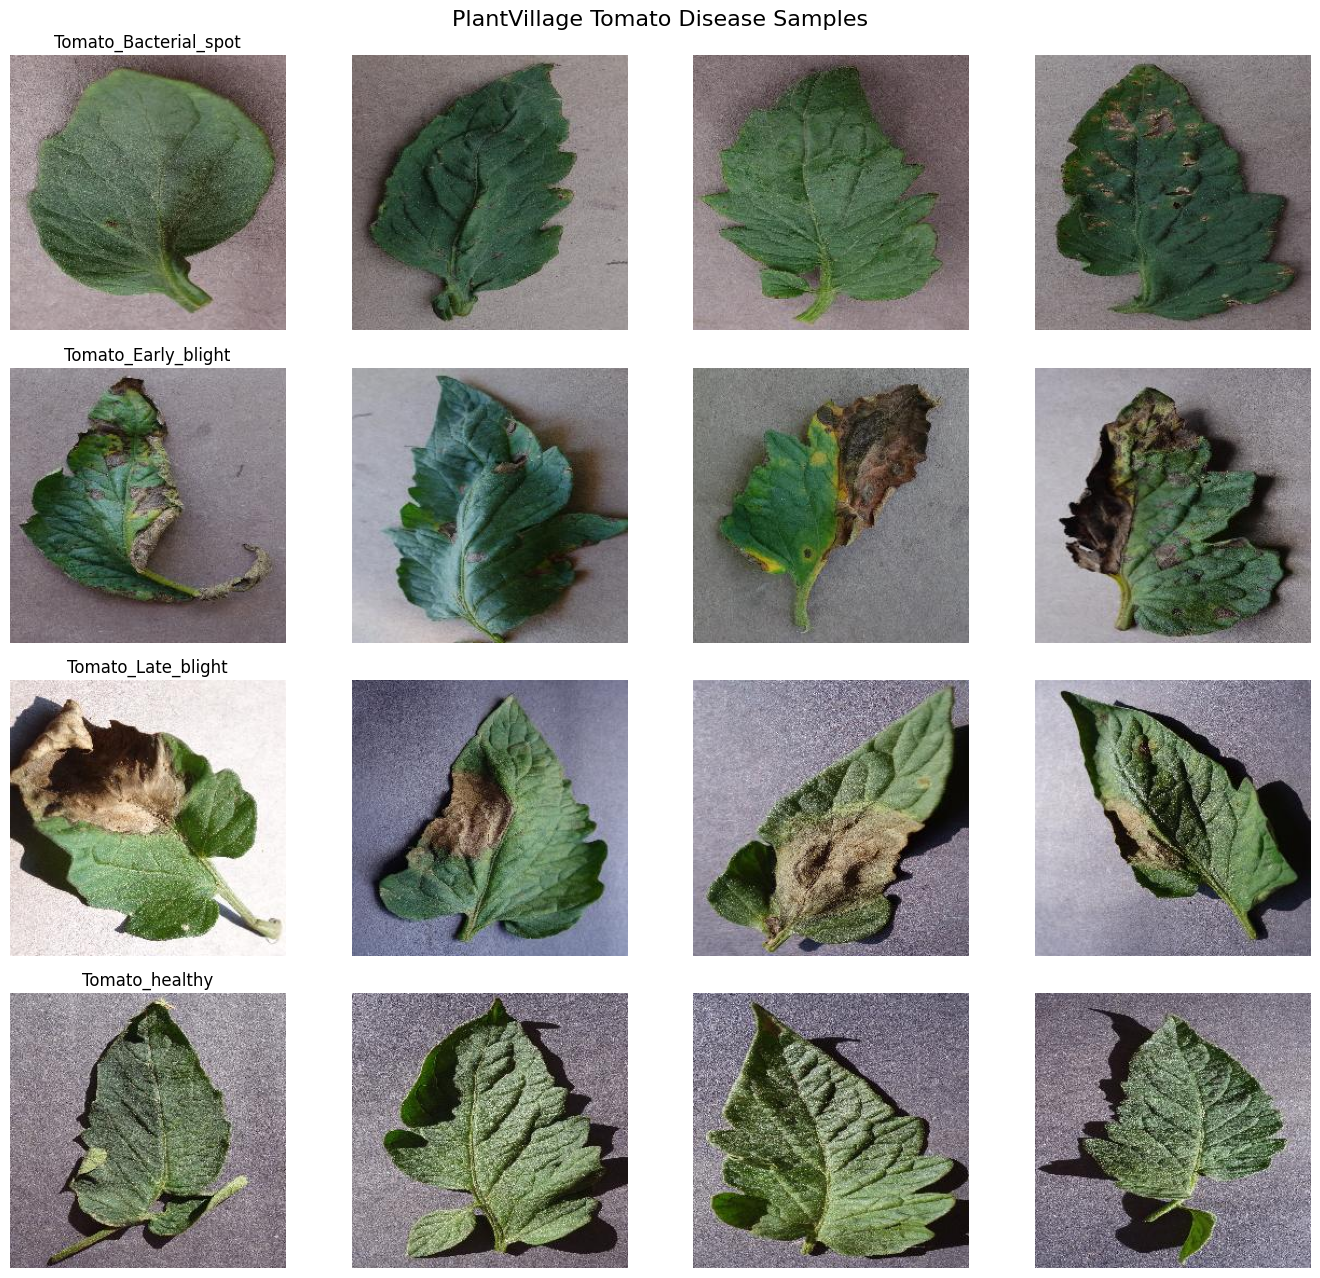

In [15]:
#5
import matplotlib.pyplot as plt
from PIL import Image
import random

random.seed(42)

fig, axes = plt.subplots(4, 4, figsize=(14, 13))

for row, class_name in enumerate(SELECTED_CLASSES):

    images = [
        p for p in CLASS_PATHS[class_name].iterdir()
        if p.suffix.lower() in IMAGE_EXTENSIONS
    ]

    selected = random.sample(images, 4)

    for col, image_path in enumerate(selected):
        with Image.open(image_path) as img:
            axes[row, col].imshow(img.convert("RGB"))

        axes[row, col].axis("off")

        if col == 0:
            axes[row, col].set_title(class_name)

plt.suptitle("PlantVillage Tomato Disease Samples", fontsize=16)
plt.tight_layout()

plt.savefig(
    OUTPUT_ROOT / "sample_images.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


                   Class  Image Count
0  Tomato_Bacterial_spot         2127
1    Tomato_Early_blight         1000
2     Tomato_Late_blight         1909
3         Tomato_healthy         1591


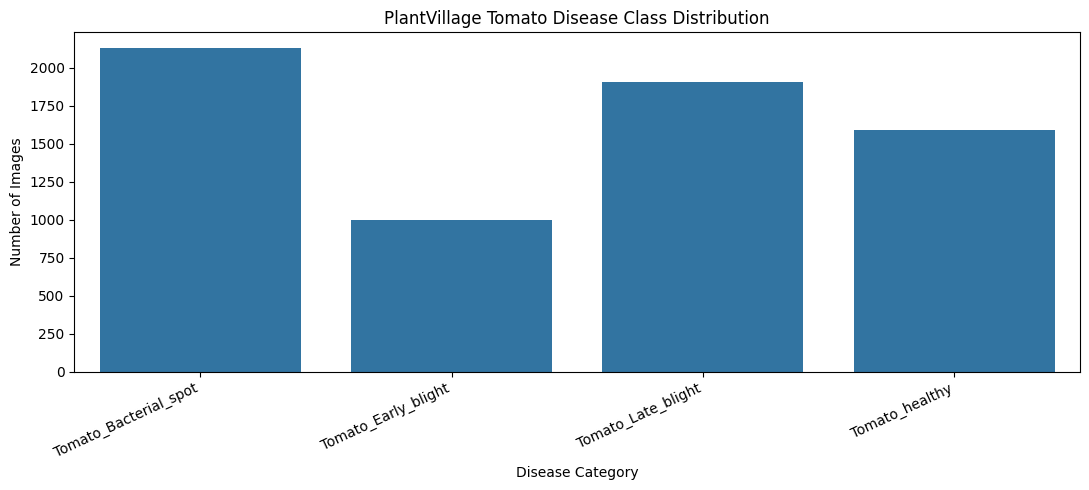

In [16]:
#6
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

class_df = pd.DataFrame([
    {
        "Class": name,
        "Image Count": sum(
            1 for p in folder.iterdir()
            if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
        )
    }
    for name, folder in CLASS_PATHS.items()
])

print(class_df)

plt.figure(figsize=(11, 5))
sns.barplot(data=class_df, x="Class", y="Image Count")

plt.title("PlantVillage Tomato Disease Class Distribution")
plt.xlabel("Disease Category")
plt.ylabel("Number of Images")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()

plt.savefig(
    OUTPUT_ROOT / "class_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [17]:
#7
import hashlib
from collections import defaultdict
from PIL import Image

image_records = []
corrupted_images = []
hash_groups = defaultdict(list)

for class_name in SELECTED_CLASSES:

    folder = CLASS_PATHS[class_name]

    for image_path in sorted(folder.iterdir()):

        if image_path.suffix.lower() not in IMAGE_EXTENSIONS:
            continue

        try:
            with Image.open(image_path) as img:
                img.verify()

            file_hash = hashlib.sha256(
                image_path.read_bytes()
            ).hexdigest()

            record = {
                "path": str(image_path),
                "class": class_name,
                "hash": file_hash
            }

            image_records.append(record)
            hash_groups[file_hash].append(record)

        except Exception as e:
            corrupted_images.append({
                "path": str(image_path),
                "error": str(e)
            })

duplicate_groups = {
    h: records
    for h, records in hash_groups.items()
    if len(records) > 1
}

print("Total images scanned:", 
      len(image_records) + len(corrupted_images))

print("Valid images:", len(image_records))
print("Corrupted images:", len(corrupted_images))
print("Exact duplicate groups:", len(duplicate_groups))
print(
    "Images involved in duplicates:",
    sum(len(v) for v in duplicate_groups.values())
)


Total images scanned: 6627
Valid images: 6627
Corrupted images: 0
Exact duplicate groups: 14
Images involved in duplicates: 28


In [18]:
#8
from collections import defaultdict
import pandas as pd

hash_to_records = defaultdict(list)

for record in image_records:
    hash_to_records[record["hash"]].append(record)

clean_records = []
ambiguous_groups = 0
removed_duplicates = 0

for file_hash, records in hash_to_records.items():

    labels = set(r["class"] for r in records)

    if len(labels) > 1:
        ambiguous_groups += 1
        continue

    records = sorted(records, key=lambda r: r["path"])

    clean_records.append(records[0])
    removed_duplicates += len(records) - 1

print("Valid images:", len(image_records))
print("Removed duplicates:", removed_duplicates)
print("Ambiguous duplicate groups:", ambiguous_groups)
print("Final clean images:", len(clean_records))


Valid images: 6627
Removed duplicates: 14
Ambiguous duplicate groups: 0
Final clean images: 6613


In [19]:
#9
from sklearn.model_selection import train_test_split

df = pd.DataFrame(clean_records)

train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    random_state=42,
    stratify=df["class"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["class"]
)

train_df = train_df.copy()
val_df = val_df.copy()
test_df = test_df.copy()

train_df["split"] = "train"
val_df["split"] = "validation"
test_df["split"] = "test"

final_df = pd.concat(
    [train_df, val_df, test_df],
    ignore_index=True
)

OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

final_df.to_csv(
    OUTPUT_ROOT / "dataset_manifest.csv",
    index=False
)

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))
print("Total images:", len(final_df))

print("\nClass-wise distribution:")
print(
    final_df.groupby(["class", "split"])
    .size()
    .unstack(fill_value=0)
)


Training images: 4629
Validation images: 992
Testing images: 992
Total images: 6613

Class-wise distribution:
split                  test  train  validation
class                                         
Tomato_Bacterial_spot   319   1489         319
Tomato_Early_blight     150    700         150
Tomato_Late_blight      285   1331         285
Tomato_healthy          238   1109         238


In [20]:
#10
# Check for duplicate leakage across dataset splits

hash_split_counts = (
    final_df.groupby("hash")["split"].nunique()
)

leaked_hashes = hash_split_counts[
    hash_split_counts > 1
]

print("Hashes appearing in multiple splits:", len(leaked_hashes))

assert len(leaked_hashes) == 0, \
    "Duplicate leakage detected!"

print("Duplicate leakage check passed!")


Hashes appearing in multiple splits: 0
Duplicate leakage check passed!


In [21]:
#11
CAPTION_TEMPLATES = {
    "Tomato_Bacterial_spot":
        "A close-up photograph of a tomato leaf affected by bacterial spot disease",

    "Tomato_Early_blight":
        "A close-up photograph of a tomato leaf affected by early blight disease",

    "Tomato_Late_blight":
        "A close-up photograph of a tomato leaf affected by late blight disease",

    "Tomato_healthy":
        "A close-up photograph of a healthy green tomato leaf"
}

train_df["caption"] = train_df["class"].map(
    CAPTION_TEMPLATES
)

train_df.to_csv(
    OUTPUT_ROOT / "lora_training_manifest.csv",
    index=False
)

print("Training manifest saved successfully!")
print(train_df[["class", "caption"]].head())


Training manifest saved successfully!
                      class                                            caption
952   Tomato_Bacterial_spot  A close-up photograph of a tomato leaf affecte...
3917     Tomato_Late_blight  A close-up photograph of a tomato leaf affecte...
1803  Tomato_Bacterial_spot  A close-up photograph of a tomato leaf affecte...
269   Tomato_Bacterial_spot  A close-up photograph of a tomato leaf affecte...
6171         Tomato_healthy  A close-up photograph of a healthy green tomat...


In [22]:
#12

import torch
import diffusers
import transformers
import accelerate
import peft
import datasets
import pandas as pd
import numpy as np
import sklearn
import platform

print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
print("Diffusers:", diffusers.__version__)
print("Transformers:", transformers.__version__)
print("Accelerate:", accelerate.__version__)
print("PEFT:", peft.__version__)
print("Datasets:", datasets.__version__)

print("\nCUDA available:", torch.cuda.is_available())

assert torch.cuda.is_available(), "Enable GPU in Kaggle!"

print("GPU:", torch.cuda.get_device_name(0))
print("GPU memory:",
      round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
      "GB")

print("\nEnvironment verification completed!")


Python: 3.13.16
PyTorch: 2.11.0+cu130
Diffusers: 0.42.0
Transformers: 5.20.2
Accelerate: 1.15.0
PEFT: 0.21.2
Datasets: 4.8.5

CUDA available: True
GPU: Tesla T4
GPU memory: 14.56 GB

Environment verification completed!


In [23]:
#13

from pathlib import Path

MODEL_ID = "stable-diffusion-v1-5/stable-diffusion-v1-5"

MODEL_REVISION = (
    "451f4fe16113bff5a5d2269ed5ad43b0592e9a14"
)

OUTPUT_ROOT = Path(
    "/kaggle/working/plant_disease_project_rank16"
)

MODEL_DIR = OUTPUT_ROOT / "stable_diffusion_model"

LORA_DATA_DIR = OUTPUT_ROOT / "lora_dataset"

BASELINE_DIR = (
    OUTPUT_ROOT / "generated_images" / "baseline"
)

LORA_RANK8_DIR = OUTPUT_ROOT / "lora_rank8"

LORA_RANK16_DIR = OUTPUT_ROOT / "lora_rank16"

for folder in [
    OUTPUT_ROOT,
    MODEL_DIR,
    LORA_DATA_DIR,
    BASELINE_DIR,
    LORA_RANK8_DIR,
    LORA_RANK16_DIR
]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project directories initialized!")

print("Dataset:", LORA_DATA_DIR)
print("Baseline:", BASELINE_DIR)
print("LoRA rank 8:", LORA_RANK8_DIR)
print("LoRA rank 16:", LORA_RANK16_DIR)


Project directories initialized!
Dataset: /kaggle/working/plant_disease_project_rank16/lora_dataset
Baseline: /kaggle/working/plant_disease_project_rank16/generated_images/baseline
LoRA rank 8: /kaggle/working/plant_disease_project_rank16/lora_rank8
LoRA rank 16: /kaggle/working/plant_disease_project_rank16/lora_rank16


In [24]:
#14
import json
import shutil

LORA_DATA_DIR = OUTPUT_ROOT / "lora_dataset"
LORA_DATA_DIR.mkdir(parents=True, exist_ok=True)

metadata_path = LORA_DATA_DIR / "metadata.jsonl"

with open(metadata_path, "w") as f:

    for index, row in train_df.reset_index(drop=True).iterrows():

        source = Path(row["path"])

        filename = f"image_{index:05d}{source.suffix.lower()}"

        destination = LORA_DATA_DIR / filename

        if not destination.exists():
            shutil.copy2(source, destination)

        metadata = {
            "file_name": filename,
            "text": row["caption"]
        }

        f.write(json.dumps(metadata) + "\n")

print("Images:", len(list(LORA_DATA_DIR.glob("image_*"))))
print("Metadata created:", metadata_path.exists())


Images: 4629
Metadata created: True


In [25]:
#15
from pathlib import Path
import json
from PIL import Image

LORA_DATA_DIR = Path(
    "/kaggle/working/plant_disease_project_rank16/lora_dataset"
)

metadata_path = LORA_DATA_DIR / "metadata.jsonl"

assert LORA_DATA_DIR.exists(), "LoRA dataset folder missing!"
assert metadata_path.exists(), "metadata.jsonl missing!"

# Read metadata
with open(metadata_path, "r") as f:
    metadata = [json.loads(line) for line in f if line.strip()]

print("Total metadata records:", len(metadata))

# Verify image files
missing_images = []
corrupted_images = []

for item in metadata:
    image_path = LORA_DATA_DIR / item["file_name"]

    if not image_path.exists():
        missing_images.append(item["file_name"])
        continue

    try:
        with Image.open(image_path) as img:
            img.verify()
    except Exception:
        corrupted_images.append(item["file_name"])

print("Missing images:", len(missing_images))
print("Corrupted images:", len(corrupted_images))

assert len(metadata) == 4629, "Unexpected training image count!"
assert len(missing_images) == 0, "Missing images detected!"
assert len(corrupted_images) == 0, "Corrupted images detected!"

print("\nLoRA dataset verification successful!")

print("\nSample metadata:")
for item in metadata[:4]:
    print(item)


Total metadata records: 4629
Missing images: 0
Corrupted images: 0

LoRA dataset verification successful!

Sample metadata:
{'file_name': 'image_00000.jpg', 'text': 'A close-up photograph of a tomato leaf affected by bacterial spot disease'}
{'file_name': 'image_00001.jpg', 'text': 'A close-up photograph of a tomato leaf affected by late blight disease'}
{'file_name': 'image_00002.jpg', 'text': 'A close-up photograph of a tomato leaf affected by bacterial spot disease'}
{'file_name': 'image_00003.jpg', 'text': 'A close-up photograph of a tomato leaf affected by bacterial spot disease'}


In [26]:
#20

import subprocess
import diffusers
from pathlib import Path

DIFFUSERS_DIR = Path(
    "/kaggle/working/diffusers"
)

TRAIN_SCRIPT = (
    DIFFUSERS_DIR
    / "examples"
    / "text_to_image"
    / "train_text_to_image_lora.py"
)

if not TRAIN_SCRIPT.exists():

    subprocess.run(
        [
            "git",
            "clone",
            "--depth", "1",
            "--branch", "v0.42.0",
            "https://github.com/huggingface/diffusers.git",
            str(DIFFUSERS_DIR)
        ],
        check=True
    )

assert TRAIN_SCRIPT.exists(), "Training script missing!"

print("Diffusers version:", diffusers.__version__)
print("Training script:", TRAIN_SCRIPT)
print("Training script ready!")


Diffusers version: 0.42.0
Training script: /kaggle/working/diffusers/examples/text_to_image/train_text_to_image_lora.py
Training script ready!


In [27]:
#21
import torch
import gc

# Release the baseline pipeline from GPU memory
if "pipe" in globals():
    del pipe

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("GPU memory cleared!")

print(
    "Allocated GPU memory:",
    round(torch.cuda.memory_allocated() / 1024**3, 2),
    "GB"
)

print(
    "Reserved GPU memory:",
    round(torch.cuda.memory_reserved() / 1024**3, 2),
    "GB"
)


GPU memory cleared!
Allocated GPU memory: 0.0 GB
Reserved GPU memory: 0.0 GB


In [28]:
#22

import importlib.util
import subprocess
import sys

torchao_installed = (
    importlib.util.find_spec("torchao") is not None
)

if torchao_installed:

    print("TorchAO detected. Removing incompatible package...")

    subprocess.run(
        [
            sys.executable,
            "-m",
            "pip",
            "uninstall",
            "-y",
            "torchao"
        ],
        check=True
    )

else:
    print("TorchAO is already absent.")

print("\nChecking environment...")

print("PyTorch:", torch.__version__)

import peft
print("PEFT:", peft.__version__)

print(
    "TorchAO installed:",
    importlib.util.find_spec("torchao") is not None
)

assert importlib.util.find_spec("torchao") is None

print("\nDependency verification successful!")


TorchAO detected. Removing incompatible package...
Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0

Checking environment...
PyTorch: 2.11.0+cu130
PEFT: 0.21.2
TorchAO installed: False

Dependency verification successful!


In [29]:
#23


import subprocess
from pathlib import Path

MODEL_ID = "stable-diffusion-v1-5/stable-diffusion-v1-5"

MODEL_REVISION = (
    "451f4fe16113bff5a5d2269ed5ad43b0592e9a14"
)

TRAIN_DATA_DIR = str(LORA_DATA_DIR)

LORA_OUTPUT_DIR = str(LORA_RANK16_DIR)

Path(LORA_OUTPUT_DIR).mkdir(
    parents=True,
    exist_ok=True
)

# Verify FP16 support in the training script
script_text = TRAIN_SCRIPT.read_text()

assert 'if args.mixed_precision == "fp16"' in script_text, (
    "Expected FP16 parameter-casting logic not found!"
)

cmd = [
    "accelerate", "launch",

    # Accelerate precision
    "--num_processes=1",
    "--mixed_precision=fp16",

    str(TRAIN_SCRIPT),

    # Diffusers training-script precision
    "--mixed_precision=fp16",

    "--pretrained_model_name_or_path",
    MODEL_ID,

    "--revision",
    MODEL_REVISION,

    "--train_data_dir",
    TRAIN_DATA_DIR,

    "--image_column=image",
    "--caption_column=text",

    "--resolution=512",
    "--center_crop",
    "--random_flip",

    "--train_batch_size=1",
    "--gradient_accumulation_steps=4",
    "--gradient_checkpointing",

    "--max_train_steps=3500",

    "--learning_rate=1e-4",
    "--lr_scheduler=cosine",
    "--lr_warmup_steps=100",

    "--max_grad_norm=1.0",

    "--rank=16",

    "--checkpointing_steps=500",
    "--checkpoints_total_limit=2",

    "--seed=42",

    "--dataloader_num_workers=2",

    "--output_dir",
    LORA_OUTPUT_DIR
]

# Preflight checks: do not start a long run if the adapter already exists.
ADAPTER_PATH = Path(LORA_OUTPUT_DIR) / "pytorch_lora_weights.safetensors"
if ADAPTER_PATH.exists():
    raise FileExistsError(
        f"Rank 16 adapter already exists: {ADAPTER_PATH}. "
        "Inspect it before deciding whether to retrain."
    )

assert importlib.util.find_spec("torchao") is None, (
    "TorchAO is still installed. Rerun the TorchAO compatibility cell."
)
assert Path(TRAIN_DATA_DIR).exists(), "LoRA training image folder is missing."
assert (Path(TRAIN_DATA_DIR) / "metadata.jsonl").exists(), "metadata.jsonl is missing."

print("Starting LoRA rank 16 training...")
print("Model:", MODEL_ID)
print("Rank: 16")
print("Precision: FP16")
print("Training steps: 3500")

subprocess.run(cmd, check=True)

print("\nLoRA rank 16 training completed!")
print("Output:", LORA_OUTPUT_DIR)


# Verify the final adapter after successful completion
assert ADAPTER_PATH.exists(), f"Final adapter not found: {ADAPTER_PATH}"
print("Final Rank 16 adapter size (MB):", round(ADAPTER_PATH.stat().st_size / (1024**2), 2))


Starting LoRA rank 16 training...
Model: stable-diffusion-v1-5/stable-diffusion-v1-5
Rank: 16
Precision: FP16
Training steps: 3500


The following values were not passed to `accelerate launch` and had defaults used instead:
	`--num_machines` was set to a value of `1`
	`--dynamo_backend` was set to a value of `'no'`
To avoid this warning pass in values for each of the problematic parameters or run `accelerate config`.
11/15/2026 07:37:13 - INFO - __main__ - [RANK 0] Distributed environment: DistributedType.NO
Num processes: 1
Process index: 0
Local process index: 0
Device: cuda

Mixed precision type: fp16

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(
11/15/2026 07:37:13 - INFO - httpx - HTTP Request: HEAD https://huggingface.co/stable-diffusion-v1-5/stable-diffusion-v1-5/resolve/main/scheduler/scheduler_config.json "HTTP/1.1 307 Temporary Redirect"
11/15/2026 07:37:13 - WARNING - huggingface_hub.utils._h


LoRA rank 16 training completed!
Output: /kaggle/working/plant_disease_project_rank16/lora_rank16
Final Rank 16 adapter size (MB): 12.2


In [31]:
from pathlib import Path
import torch
import os

PROJECT_ROOT = Path("/kaggle/working/plant_disease_project_rank16")
LORA_DIR = PROJECT_ROOT / "lora_rank16"

ADAPTER_PATH = LORA_DIR / "pytorch_lora_weights.safetensors"

if not ADAPTER_PATH.exists():
    raise FileNotFoundError(
        f"Final LoRA adapter not found: {ADAPTER_PATH}\n"
        "Check the training output directory before proceeding."
    )

print("Rank 16 adapter found!")
print("Path:", ADAPTER_PATH)
print("Size (MB):", round(ADAPTER_PATH.stat().st_size / (1024**2), 2))
print("CUDA available:", torch.cuda.is_available())

assert torch.cuda.is_available(), "Kaggle GPU is not enabled."

Rank 16 adapter found!
Path: /kaggle/working/plant_disease_project_rank16/lora_rank16/pytorch_lora_weights.safetensors
Size (MB): 12.2
CUDA available: True


In [32]:

import torch
from diffusers import StableDiffusionPipeline

MODEL_ID = "stable-diffusion-v1-5/stable-diffusion-v1-5"
MODEL_REVISION = "451f4fe16113bff5a5d2269ed5ad43b0592e9a14"

print("Loading Stable Diffusion 1.5...")

pipe_lora = StableDiffusionPipeline.from_pretrained(
    MODEL_ID,
    revision=MODEL_REVISION,
    dtype=torch.float16,
    use_safetensors=True,
    cache_dir=str(PROJECT_ROOT / "model_cache")
)

# Memory optimization
pipe_lora.enable_attention_slicing()

# Load trained Rank 16 adapter
print("Loading LoRA Rank 16 adapter...")

pipe_lora.load_lora_weights(
    str(LORA_DIR),
    weight_name="pytorch_lora_weights.safetensors"
)

pipe_lora = pipe_lora.to("cuda")

print("\nStable Diffusion 1.5 + LoRA Rank 16 loaded successfully!")

print(
    "GPU memory allocated:",
    round(torch.cuda.memory_allocated() / (1024**3), 2),
    "GB"
)


Loading Stable Diffusion 1.5...


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading LoRA Rank 16 adapter...


No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new



Stable Diffusion 1.5 + LoRA Rank 16 loaded successfully!
GPU memory allocated: 2.58 GB


In [33]:
CLASSES = SELECTED_CLASSES

#17

PROMPTS = {
    "Tomato_Bacterial_spot":
        "A realistic close-up botanical photograph of a tomato leaf affected by bacterial spot disease, showing small dark lesions on the leaf surface, natural lighting, detailed leaf texture",

    "Tomato_Early_blight":
        "A realistic close-up botanical photograph of a tomato leaf affected by early blight disease, showing characteristic brown concentric lesions and yellowing, natural lighting, detailed leaf texture",

    "Tomato_Late_blight":
        "A realistic close-up botanical photograph of a tomato leaf affected by late blight disease, showing irregular dark brown lesions and damaged leaf tissue, natural lighting, detailed leaf texture",

    "Tomato_healthy":
        "A realistic close-up botanical photograph of a healthy green tomato leaf, showing natural veins, uniform green coloration and detailed leaf texture"
}

NEGATIVE_PROMPT = (
    "cartoon, painting, illustration, blurry, low quality, "
    "watermark, text, distorted leaves, artificial colors"
)

print("Number of classes:", len(PROMPTS))


Number of classes: 4


In [34]:
from pathlib import Path
from PIL import Image
from tqdm.auto import tqdm
import numpy as np
import pandas as pd
import gc

NUM_IMAGES_PER_CLASS = 100
IMAGE_SIZE = 512
INFERENCE_STEPS = 25
GUIDANCE_SCALE = 7.5
MAX_RETRIES = 5

LORA16_GENERATED_DIR = (
    PROJECT_ROOT / "generated_images" / "lora_rank16"
)

LORA16_GENERATED_DIR.mkdir(parents=True, exist_ok=True)

def is_black_image(image):
    arr = np.asarray(image.convert("RGB"))
    return arr.mean() < 5 and arr.std() < 3

records = []

for class_index, class_name in enumerate(CLASSES):

    print(f"\nGenerating: {class_name}")

    class_dir = LORA16_GENERATED_DIR / class_name
    class_dir.mkdir(parents=True, exist_ok=True)

    for image_index in tqdm(range(NUM_IMAGES_PER_CLASS)):

        image_name = f"{class_name}_{image_index + 1:04d}.png"
        image_path = class_dir / image_name

        if image_path.exists():
            raise FileExistsError(
                f"{image_path} already exists. Use a fresh output folder "
                "or verify the previous generation run."
            )

        success = False
        used_seed = None

        for attempt in range(MAX_RETRIES):

            seed = 80000 + class_index * 10000 + image_index * 10 + attempt
            generator = torch.Generator("cuda").manual_seed(seed)

            with torch.inference_mode():
                result = pipe_lora(
                    prompt=PROMPTS[class_name],
                    negative_prompt=NEGATIVE_PROMPT,
                    height=IMAGE_SIZE,
                    width=IMAGE_SIZE,
                    num_inference_steps=INFERENCE_STEPS,
                    guidance_scale=GUIDANCE_SCALE,
                    generator=generator
                )

            generated_image = result.images[0]

            flags = getattr(result, "nsfw_content_detected", None)
            flagged = (
                flags is not None
                and len(flags) > 0
                and bool(flags[0])
            )

            if flagged or is_black_image(generated_image):
                continue

            generated_image.save(image_path)
            used_seed = seed
            success = True
            break

        records.append({
            "class": class_name,
            "image_name": image_name,
            "seed": used_seed,
            "model": MODEL_ID,
            "method": "Stable_Diffusion_1.5_LoRA_Rank16",
            "prompt": PROMPTS[class_name],
            "image_path": str(image_path),
            "status": "success" if success else "failed"
        })

    gc.collect()
    torch.cuda.empty_cache()

metadata_df = pd.DataFrame(records)

metadata_path = LORA16_GENERATED_DIR / "generation_metadata.csv"
metadata_df.to_csv(metadata_path, index=False)

print("\nLoRA Rank 16 generation finished.")
print(metadata_df.groupby(["class", "status"]).size())
print("Metadata saved:", metadata_path)


Generating: Tomato_Bacterial_spot


  0%|          | 0/100 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

... (403 outputs left out)

  0%|          | 0/25 [00:00<?, ?it/s]

Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.


  0%|          | 0/25 [00:00<?, ?it/s]


LoRA Rank 16 generation finished.
class                  status 
Tomato_Bacterial_spot  success    100
Tomato_Early_blight    success    100
Tomato_Late_blight     success    100
Tomato_healthy         success    100
dtype: int64
Metadata saved: /kaggle/working/plant_disease_project_rank16/generated_images/lora_rank16/generation_metadata.csv


In [35]:
metadata_df = pd.read_csv(
    LORA16_GENERATED_DIR / "generation_metadata.csv"
)

valid_counts = {}
black_count = 0
missing_count = 0

for class_name in CLASSES:

    class_rows = metadata_df[
        (metadata_df["class"] == class_name) &
        (metadata_df["status"] == "success")
    ]

    count = 0

    for _, row in class_rows.iterrows():

        image_path = Path(row["image_path"])

        if not image_path.exists():
            missing_count += 1
            continue

        image = Image.open(image_path).convert("RGB")

        if is_black_image(image):
            black_count += 1
        else:
            count += 1

    valid_counts[class_name] = count

print("Valid images per class:")
for class_name, count in valid_counts.items():
    print(class_name, ":", count)

total_valid = sum(valid_counts.values())

print("\nTotal valid:", total_valid)
print("Black images:", black_count)
print("Missing images:", missing_count)

assert total_valid == 400, "Expected 400 valid images."
assert black_count == 0, "Black images were detected."
assert missing_count == 0, "Some images are missing."

print("All 400 Rank 16 images verified.")

Valid images per class:
Tomato_Bacterial_spot : 100
Tomato_Early_blight : 100
Tomato_Late_blight : 100
Tomato_healthy : 100

Total valid: 400
Black images: 0
Missing images: 0
All 400 Rank 16 images verified.


In [36]:
from pathlib import Path

DATASET_COPIES = [
    Path("/kaggle/input/datasets/emmarex/plantdisease/PlantVillage"),
    Path("/kaggle/input/datasets/emmarex/plantdisease/plantvillage/PlantVillage")
]

CLASSES = [
    "Tomato_Bacterial_spot",
    "Tomato_Early_blight",
    "Tomato_Late_blight",
    "Tomato_healthy"
]

for dataset_root in DATASET_COPIES:

    print("\nDataset:", dataset_root)

    total = 0

    for class_name in CLASSES:
        class_dir = dataset_root / class_name

        if class_dir.exists():
            count = len([
                p for p in class_dir.iterdir()
                if p.is_file() and p.suffix.lower() in [".jpg", ".jpeg", ".png"]
            ])
        else:
            count = 0

        total += count
        print(f"{class_name}: {count}")

    print("Total:", total)


Dataset: /kaggle/input/datasets/emmarex/plantdisease/PlantVillage
Tomato_Bacterial_spot: 2127
Tomato_Early_blight: 1000
Tomato_Late_blight: 1909
Tomato_healthy: 1591
Total: 6627

Dataset: /kaggle/input/datasets/emmarex/plantdisease/plantvillage/PlantVillage
Tomato_Bacterial_spot: 2127
Tomato_Early_blight: 1000
Tomato_Late_blight: 1909
Tomato_healthy: 1591
Total: 6627


In [37]:
import pandas as pd
from pathlib import Path

manifest_path = PROJECT_ROOT / "dataset_manifest.csv"
df = pd.read_csv(manifest_path)

print("Images per split:")
print(df["split"].value_counts())

print("\nClass-wise split distribution:")
display(pd.crosstab(df["class"], df["split"]))

print("\nMissing image paths:")
df["exists"] = df["path"].apply(lambda x: Path(x).is_file())
print("Missing:", (~df["exists"]).sum())

Images per split:
split
train         4629
validation     992
test           992
Name: count, dtype: int64

Class-wise split distribution:


split,test,train,validation
class,,,
Tomato_Bacterial_spot,319,1489,319
Tomato_Early_blight,150,700,150
Tomato_Late_blight,285,1331,285
Tomato_healthy,238,1109,238



Missing image paths:
Missing: 0


In [38]:
from pathlib import Path
import pandas as pd
import shutil

PROJECT_ROOT = Path("/kaggle/working/plant_disease_project_rank16")

manifest_path = PROJECT_ROOT / "dataset_manifest.csv"
df = pd.read_csv(manifest_path)

REAL_DATASET_DIR = PROJECT_ROOT / "real_dataset"

# Verify original records
assert len(df) == 6613
assert df["path"].apply(lambda x: Path(x).is_file()).all()

expected_counts = {
    "train": 4629,
    "validation": 992,
    "test": 992
}

assert df["split"].value_counts().to_dict() == expected_counts

# Create directories and link images
for _, row in df.iterrows():

    source = Path(row["path"])
    split = row["split"]
    class_name = row["class"]

    destination_dir = REAL_DATASET_DIR / split / class_name
    destination_dir.mkdir(parents=True, exist_ok=True)

    destination = destination_dir / source.name

    if destination.exists():
        continue

    try:
        destination.hardlink_to(source)
    except OSError:
        shutil.copy2(source, destination)

print("Real dataset reconstruction completed!")

Real dataset reconstruction completed!


In [39]:
from torchvision import datasets

REAL_TRAIN_DIR = REAL_DATASET_DIR / "train"
REAL_VAL_DIR = REAL_DATASET_DIR / "validation"
REAL_TEST_DIR = REAL_DATASET_DIR / "test"

for split_name, split_dir in [
    ("Train", REAL_TRAIN_DIR),
    ("Validation", REAL_VAL_DIR),
    ("Test", REAL_TEST_DIR)
]:
    dataset = datasets.ImageFolder(split_dir)

    print(f"\n{split_name}: {len(dataset)} images")
    print("Class mapping:", dataset.class_to_idx)
    print("Class counts:", {
        cls: sum(1 for _, label in dataset.samples
                 if dataset.classes[label] == cls)
        for cls in dataset.classes
    })


Train: 4629 images
Class mapping: {'Tomato_Bacterial_spot': 0, 'Tomato_Early_blight': 1, 'Tomato_Late_blight': 2, 'Tomato_healthy': 3}
Class counts: {'Tomato_Bacterial_spot': 1489, 'Tomato_Early_blight': 700, 'Tomato_Late_blight': 1331, 'Tomato_healthy': 1109}

Validation: 992 images
Class mapping: {'Tomato_Bacterial_spot': 0, 'Tomato_Early_blight': 1, 'Tomato_Late_blight': 2, 'Tomato_healthy': 3}
Class counts: {'Tomato_Bacterial_spot': 319, 'Tomato_Early_blight': 150, 'Tomato_Late_blight': 285, 'Tomato_healthy': 238}

Test: 992 images
Class mapping: {'Tomato_Bacterial_spot': 0, 'Tomato_Early_blight': 1, 'Tomato_Late_blight': 2, 'Tomato_healthy': 3}
Class counts: {'Tomato_Bacterial_spot': 319, 'Tomato_Early_blight': 150, 'Tomato_Late_blight': 285, 'Tomato_healthy': 238}


In [40]:
from torchvision import datasets
from pathlib import Path

real_train = datasets.ImageFolder(REAL_TRAIN_DIR)
real_val = datasets.ImageFolder(REAL_VAL_DIR)
real_test = datasets.ImageFolder(REAL_TEST_DIR)
SYNTHETIC_DIR = PROJECT_ROOT / "generated_images" / "lora_rank16"
synthetic_train = datasets.ImageFolder(SYNTHETIC_DIR)

# Verify class mappings
assert real_train.class_to_idx == real_val.class_to_idx
assert real_train.class_to_idx == real_test.class_to_idx
assert real_train.class_to_idx == synthetic_train.class_to_idx

# Verify image counts
assert len(real_train) == 4629
assert len(real_val) == 992
assert len(real_test) == 992
assert len(synthetic_train) == 400

print("All dataset checks passed!")

print("\nClass mapping:", real_train.class_to_idx)
print("Real training:", len(real_train))
print("Synthetic training:", len(synthetic_train))
print("Combined training:", len(real_train) + len(synthetic_train))
print("Validation:", len(real_val))
print("Testing:", len(real_test))

All dataset checks passed!

Class mapping: {'Tomato_Bacterial_spot': 0, 'Tomato_Early_blight': 1, 'Tomato_Late_blight': 2, 'Tomato_healthy': 3}
Real training: 4629
Synthetic training: 400
Combined training: 5029
Validation: 992
Testing: 992


In [41]:
import os
import json
import time
import random
import copy
import gc
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

from pathlib import Path
from torch.utils.data import DataLoader, ConcatDataset
from torchvision import datasets, transforms, models
from torchvision.models import ResNet18_Weights

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from tqdm.auto import tqdm

# --------------------------------------------------
# PROJECT PATHS
# --------------------------------------------------

PROJECT_ROOT = Path("/kaggle/working/plant_disease_project_rank16")

REAL_DATASET_DIR = PROJECT_ROOT / "real_dataset"

REAL_TRAIN_DIR = REAL_DATASET_DIR / "train"
REAL_VAL_DIR = REAL_DATASET_DIR / "validation"
REAL_TEST_DIR = REAL_DATASET_DIR / "test"

BASELINE_SYNTHETIC_DIR = (
    PROJECT_ROOT / "generated_images" / "baseline"
)

LORA_SYNTHETIC_DIR = (
    PROJECT_ROOT / "generated_images" / "lora_rank16"
)

RESULTS_ROOT = PROJECT_ROOT / "results"

# --------------------------------------------------
# CLASSIFIER CONFIGURATION
# --------------------------------------------------

SEED = 42
BATCH_SIZE = 32
NUM_CLASSES = 4
IMAGE_SIZE = 224
NUM_WORKERS = 2

EPOCHS = 15
PATIENCE = 4

LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# --------------------------------------------------
# DATA TRANSFORMS
# --------------------------------------------------

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("\nClassifier configuration ready!")

Device: cuda
GPU: Tesla T4

Classifier configuration ready!


In [43]:
def set_seed(seed):

    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def run_classifier_experiment(
    synthetic_dir,
    experiment_name,
    seed=42
):

    print("\n" + "=" * 60)
    print("EXPERIMENT:", experiment_name)
    print("=" * 60)

    # Prevent accidental overwriting of previous results
    RESULT_DIR = RESULTS_ROOT / experiment_name

    if RESULT_DIR.exists() and any(RESULT_DIR.iterdir()):
        raise FileExistsError(
            f"Results already exist: {RESULT_DIR}. "
            "Choose a new output folder or inspect the existing results."
        )

    MODEL_DIR = RESULT_DIR / "models"
    MODEL_DIR.mkdir(parents=True, exist_ok=True)

    # --------------------------------------------------
    # 1. LOAD DATASETS
    # --------------------------------------------------

    set_seed(seed)

    real_train = datasets.ImageFolder(
        REAL_TRAIN_DIR,
        transform=train_transform
    )

    synthetic_train = datasets.ImageFolder(
        synthetic_dir,
        transform=train_transform
    )

    real_val = datasets.ImageFolder(
        REAL_VAL_DIR,
        transform=eval_transform
    )

    real_test = datasets.ImageFolder(
        REAL_TEST_DIR,
        transform=eval_transform
    )

    assert real_train.class_to_idx == synthetic_train.class_to_idx
    assert real_train.class_to_idx == real_val.class_to_idx
    assert real_train.class_to_idx == real_test.class_to_idx

    assert len(real_train) == 4629
    assert len(synthetic_train) == 400
    assert len(real_val) == 992
    assert len(real_test) == 992

    train_dataset = ConcatDataset([
        real_train,
        synthetic_train
    ])

    # --------------------------------------------------
    # 2. DATA LOADERS
    # --------------------------------------------------

    loader_generator = torch.Generator()
    loader_generator.manual_seed(seed)

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=NUM_WORKERS,
        pin_memory=torch.cuda.is_available(),
        generator=loader_generator
    )

    val_loader = DataLoader(
        real_val,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=torch.cuda.is_available()
    )

    test_loader = DataLoader(
        real_test,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=torch.cuda.is_available()
    )

    print("\nDataset verification:")
    print("Real training:", len(real_train))
    print("Synthetic training:", len(synthetic_train))
    print("Combined training:", len(train_dataset))
    print("Validation:", len(real_val))
    print("Testing:", len(real_test))

    # --------------------------------------------------
    # 3. INITIALIZE RESNET-18
    # --------------------------------------------------

    weights = ResNet18_Weights.DEFAULT

    model = models.resnet18(weights=weights)

    model.fc = nn.Linear(
        model.fc.in_features,
        NUM_CLASSES
    )

    model = model.to(device)

    criterion = nn.CrossEntropyLoss()

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="max",
        factor=0.5,
        patience=2
    )

    # --------------------------------------------------
    # 4. TRAINING
    # --------------------------------------------------

    best_val_accuracy = 0.0
    best_state = None

    epochs_without_improvement = 0

    history = []

    start_time = time.time()

    for epoch in range(EPOCHS):

        model.train()

        running_loss = 0.0
        correct = 0
        total = 0

        progress = tqdm(
            train_loader,
            desc=f"Epoch {epoch + 1}/{EPOCHS}"
        )

        for images, labels in progress:

            images = images.to(
                device,
                non_blocking=True
            )

            labels = labels.to(
                device,
                non_blocking=True
            )

            optimizer.zero_grad(set_to_none=True)

            outputs = model(images)

            loss = criterion(outputs, labels)

            loss.backward()

            optimizer.step()

            running_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)

            correct += (
                predictions == labels
            ).sum().item()

            total += labels.size(0)

            progress.set_postfix(
                loss=f"{loss.item():.4f}"
            )

        train_loss = running_loss / total
        train_accuracy = correct / total

        # --------------------------------------------------
        # 5. VALIDATION
        # --------------------------------------------------

        model.eval()

        val_loss_sum = 0.0
        val_correct = 0
        val_total = 0

        with torch.inference_mode():

            for images, labels in val_loader:

                images = images.to(
                    device,
                    non_blocking=True
                )

                labels = labels.to(
                    device,
                    non_blocking=True
                )

                outputs = model(images)

                loss = criterion(outputs, labels)

                val_loss_sum += (
                    loss.item() * images.size(0)
                )

                predictions = outputs.argmax(dim=1)

                val_correct += (
                    predictions == labels
                ).sum().item()

                val_total += labels.size(0)

        val_loss = val_loss_sum / val_total
        val_accuracy = val_correct / val_total

        scheduler.step(val_accuracy)

        history.append({
            "epoch": epoch + 1,
            "train_loss": train_loss,
            "train_accuracy": train_accuracy,
            "val_loss": val_loss,
            "val_accuracy": val_accuracy
        })

        print(
            f"\nEpoch {epoch + 1}/{EPOCHS} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_accuracy:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Acc: {val_accuracy:.4f}"
        )

        # Save best validation model

        if val_accuracy > best_val_accuracy:

            best_val_accuracy = val_accuracy

            best_state = {
                key: value.detach().cpu().clone()
                for key, value in model.state_dict().items()
            }

            epochs_without_improvement = 0

            torch.save({
                "model_state_dict": best_state,
                "class_to_idx": real_train.class_to_idx,
                "seed": seed,
                "best_val_accuracy": best_val_accuracy
            }, MODEL_DIR / "best_resnet18.pth")

        else:

            epochs_without_improvement += 1

        if epochs_without_improvement >= PATIENCE:

            print("\nEarly stopping triggered.")
            break

    training_time = time.time() - start_time

    if best_state is None:
        raise RuntimeError("No valid best model was saved.")

    # Restore best validation model
    model.load_state_dict(best_state)

    # Save training history
    history_df = pd.DataFrame(history)

    history_df.to_csv(
        RESULT_DIR / "training_history.csv",
        index=False
    )

    print("\nBest validation accuracy:", best_val_accuracy)
    print(
        "Training time (minutes):",
        round(training_time / 60, 2)
    )

    # --------------------------------------------------
    # 6. TEST EVALUATION
    # --------------------------------------------------

    model.eval()

    y_true = []
    y_pred = []

    with torch.inference_mode():

        for images, labels in tqdm(
            test_loader,
            desc="Testing"
        ):

            images = images.to(
                device,
                non_blocking=True
            )

            outputs = model(images)

            predictions = outputs.argmax(dim=1)

            y_pred.extend(
                predictions.cpu().numpy()
            )

            y_true.extend(
                labels.numpy()
            )

    class_names = [
        name for name, index in sorted(
            real_train.class_to_idx.items(),
            key=lambda item: item[1]
        )
    ]

    accuracy = accuracy_score(y_true, y_pred)

    precision = precision_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    macro_f1 = f1_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    # --------------------------------------------------
    # 7. SAVE METRICS
    # --------------------------------------------------

    metrics = {
        "experiment": experiment_name,
        "classifier": "ResNet18",
        "seed": seed,
        "accuracy": accuracy,
        "macro_precision": precision,
        "macro_recall": recall,
        "macro_f1": macro_f1,
        "training_time_minutes": training_time / 60,
        "real_training_images": len(real_train),
        "synthetic_training_images": len(synthetic_train),
        "combined_training_images": len(train_dataset),
        "validation_images": len(real_val),
        "test_images": len(real_test)
    }

    pd.DataFrame([metrics]).to_csv(
        RESULT_DIR / "metrics.csv",
        index=False
    )

    report = classification_report(
        y_true,
        y_pred,
        target_names=class_names,
        output_dict=True,
        zero_division=0
    )

    pd.DataFrame(report).transpose().to_csv(
        RESULT_DIR / "classification_report.csv"
    )

    predictions_df = pd.DataFrame({
        "actual_class": [
            class_names[i] for i in y_true
        ],
        "predicted_class": [
            class_names[i] for i in y_pred
        ]
    })

    predictions_df.to_csv(
        RESULT_DIR / "predictions.csv",
        index=False
    )

    # --------------------------------------------------
    # 8. SAVE LOSS AND ACCURACY CURVES
    # --------------------------------------------------

    plt.figure(figsize=(8, 5))

    plt.plot(
        history_df["epoch"],
        history_df["train_loss"],
        label="Training Loss"
    )

    plt.plot(
        history_df["epoch"],
        history_df["val_loss"],
        label="Validation Loss"
    )

    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title(f"ResNet-18 Loss - {experiment_name}")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()

    plt.savefig(
        RESULT_DIR / "loss_curve.png",
        dpi=300
    )

    plt.show()
    plt.close()

    plt.figure(figsize=(8, 5))

    plt.plot(
        history_df["epoch"],
        history_df["train_accuracy"],
        label="Training Accuracy"
    )

    plt.plot(
        history_df["epoch"],
        history_df["val_accuracy"],
        label="Validation Accuracy"
    )

    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.title(f"ResNet-18 Accuracy - {experiment_name}")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()

    plt.savefig(
        RESULT_DIR / "accuracy_curve.png",
        dpi=300
    )

    plt.show()
    plt.close()

    # --------------------------------------------------
    # 9. CONFUSION MATRIX
    # --------------------------------------------------

    cm = confusion_matrix(
        y_true,
        y_pred
    )

    plt.figure(figsize=(8, 6))

    plt.imshow(cm, interpolation="nearest")
    plt.colorbar()

    plt.xticks(
        range(len(class_names)),
        class_names,
        rotation=45,
        ha="right"
    )

    plt.yticks(
        range(len(class_names)),
        class_names
    )

    for i in range(len(class_names)):
        for j in range(len(class_names)):
            plt.text(
                j, i,
                str(cm[i, j]),
                ha="center",
                va="center"
            )

    plt.xlabel("Predicted Class")
    plt.ylabel("Actual Class")

    plt.title(
        f"Confusion Matrix - {experiment_name}"
    )

    plt.tight_layout()

    plt.savefig(
        RESULT_DIR / "confusion_matrix.png",
        dpi=300
    )

    plt.show()
    plt.close()

    # --------------------------------------------------
    # 10. SAVE EXPERIMENT CONFIGURATION
    # --------------------------------------------------

    experiment_config = {
        "experiment": experiment_name,
        "classifier": "ResNet18",
        "classifier_pretrained": "ImageNet",
        "real_training_images": len(real_train),
        "synthetic_training_images": len(synthetic_train),
        "validation_images": len(real_val),
        "test_images": len(real_test),
        "image_size": IMAGE_SIZE,
        "batch_size": BATCH_SIZE,
        "epochs_max": EPOCHS,
        "early_stopping_patience": PATIENCE,
        "seed": seed,
        "learning_rate": LEARNING_RATE,
        "weight_decay": WEIGHT_DECAY,
        "optimizer": "AdamW",
        "scheduler": "ReduceLROnPlateau",
        "best_validation_accuracy": float(best_val_accuracy),
        "test_metrics": metrics
    }

    with open(
        RESULT_DIR / "config.json",
        "w"
    ) as f:

        json.dump(
            experiment_config,
            f,
            indent=4
        )

    # --------------------------------------------------
    # 11. FINAL SUMMARY
    # --------------------------------------------------

    print("\n" + "=" * 50)
    print("FINAL RESULTS:", experiment_name)
    print("=" * 50)

    print(f"Accuracy:  {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall:    {recall:.4f}")
    print(f"Macro F1:  {macro_f1:.4f}")

    print("\nClassification report:")

    print(classification_report(
        y_true,
        y_pred,
        target_names=class_names,
        zero_division=0
    ))

    print("\nResults saved in:", RESULT_DIR)

    del model
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return metrics


EXPERIMENT: experiment_lora_rank16

Dataset verification:
Real training: 4629
Synthetic training: 400
Combined training: 5029
Validation: 992
Testing: 992
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 218MB/s]


Epoch 1/15:   0%|          | 0/158 [00:00<?, ?it/s]


Epoch 1/15 | Train Loss: 0.2019 | Train Acc: 0.9268 | Val Loss: 0.0553 | Val Acc: 0.9889


Epoch 2/15:   0%|          | 0/158 [00:00<?, ?it/s]


Epoch 2/15 | Train Loss: 0.0717 | Train Acc: 0.9741 | Val Loss: 0.0614 | Val Acc: 0.9859


... (10 outputs left out)

Epoch 7/15:   0%|          | 0/158 [00:00<?, ?it/s]

Exception ignored in: Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7d54b1e3a200><function _MultiProcessingDataLoaderIter.__del__ at 0x7d54b1e3a200>
Traceback (most recent call last):

Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
      File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
self._shutdown_workers()    
self._shutdown_workers()  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers

      File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
if w.is_alive():    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive

      File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
assert self._parent_pid == os.getpid(), 'can only test a


Epoch 7/15 | Train Loss: 0.0116 | Train Acc: 0.9966 | Val Loss: 0.0314 | Val Acc: 0.9929

Early stopping triggered.

Best validation accuracy: 0.9949596774193549
Training time (minutes): 2.69


Testing:   0%|          | 0/31 [00:00<?, ?it/s]

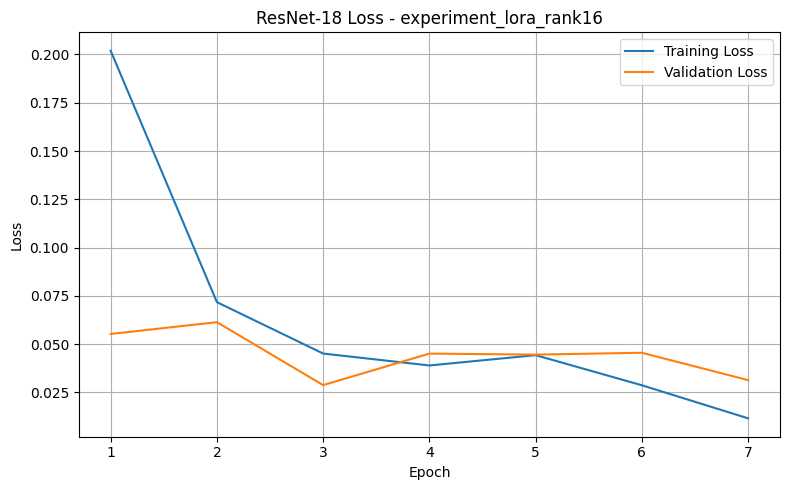

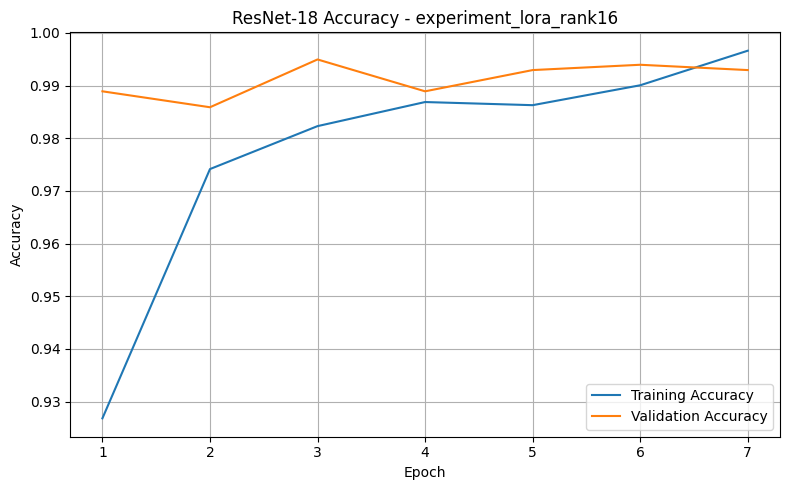

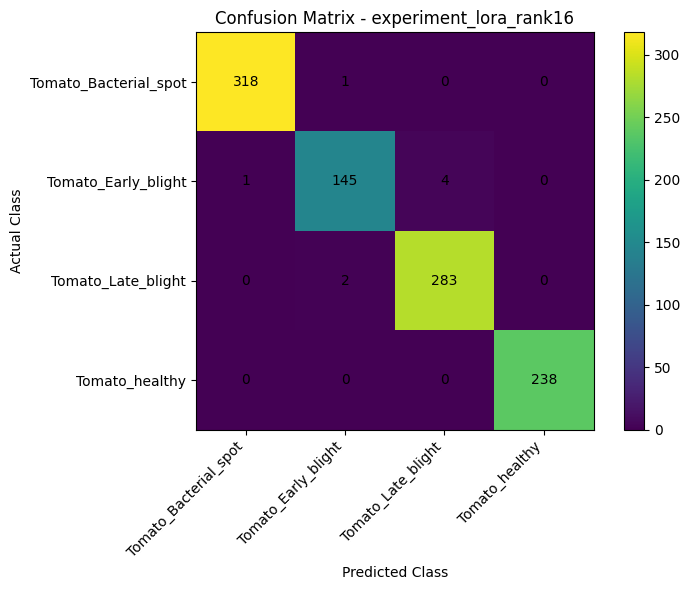


FINAL RESULTS: experiment_lora_rank16
Accuracy:  0.9919
Precision: 0.9907
Recall:    0.9891
Macro F1:  0.9899

Classification report:
                       precision    recall  f1-score   support

Tomato_Bacterial_spot       1.00      1.00      1.00       319
  Tomato_Early_blight       0.98      0.97      0.97       150
   Tomato_Late_blight       0.99      0.99      0.99       285
       Tomato_healthy       1.00      1.00      1.00       238

             accuracy                           0.99       992
            macro avg       0.99      0.99      0.99       992
         weighted avg       0.99      0.99      0.99       992


Results saved in: /kaggle/working/plant_disease_project_rank16/results/experiment_lora_rank16


In [44]:
    lora_rank16_metrics = run_classifier_experiment(
    synthetic_dir=LORA_SYNTHETIC_DIR,
    experiment_name="experiment_lora_rank16",
    seed=42
)

In [45]:
import pandas as pd

previous_results = pd.DataFrame([
    {
        "experiment": "experiment_baseline",
        "accuracy": 0.986895,
        "macro_precision": 0.982018,
        "macro_recall": 0.986415,
        "macro_f1": 0.984110,
        "training_time_minutes": 2.673155
    },
    {
        "experiment": "experiment_lora_rank8",
        "accuracy": 0.985887,
        "macro_precision": 0.987347,
        "macro_recall": 0.980815,
        "macro_f1": 0.983789,
        "training_time_minutes": 2.611377
    }
])

rank16_metrics_df = pd.read_csv(
    RESULTS_ROOT / "experiment_lora_rank16" / "metrics.csv"
)

columns = [
    "experiment", "accuracy", "macro_precision",
    "macro_recall", "macro_f1", "training_time_minutes"
]

comparison = pd.concat(
    [previous_results, rank16_metrics_df[columns]],
    ignore_index=True
)

display(comparison.style.format({
    "accuracy": "{:.6f}",
    "macro_precision": "{:.6f}",
    "macro_recall": "{:.6f}",
    "macro_f1": "{:.6f}",
    "training_time_minutes": "{:.3f}"
}))

comparison.to_csv(
    RESULTS_ROOT / "final_three_experiment_comparison.csv",
    index=False
)

print("Saved:", RESULTS_ROOT / "final_three_experiment_comparison.csv")


,experiment,accuracy,macro_precision,macro_recall,macro_f1,training_time_minutes
0,experiment_baseline,0.986895,0.982018,0.986415,0.984110,2.673
1,experiment_lora_rank8,0.985887,0.987347,0.980815,0.983789,2.611
2,experiment_lora_rank16,0.991935,0.990664,0.989129,0.989883,2.686


Saved: /kaggle/working/plant_disease_project_rank16/results/final_three_experiment_comparison.csv


In [46]:
import zipfile
from pathlib import Path

ZIP_PATH = PROJECT_ROOT / "lora_rank16_experiment_backup.zip"

with zipfile.ZipFile(ZIP_PATH, "w", zipfile.ZIP_DEFLATED) as zipf:
    for folder in [
        LORA_OUTPUT_DIR,
        LORA16_GENERATED_DIR,
        RESULTS_ROOT,
        LORA_DATA_DIR,
        REAL_DATASET_DIR
    ]:
        folder = Path(folder)
        if folder.exists():
            for file_path in folder.rglob("*"):
                if file_path.is_file():
                    zipf.write(
                        file_path,
                        file_path.relative_to(PROJECT_ROOT)
                    )

    for file_path in [
        PROJECT_ROOT / "dataset_manifest.csv",
        PROJECT_ROOT / "lora_training_manifest.csv"
    ]:
        if file_path.exists():
            zipf.write(file_path, file_path.relative_to(PROJECT_ROOT))

print("Backup created:", ZIP_PATH)
print("Size (MB):", round(ZIP_PATH.stat().st_size / (1024 * 1024), 2))


Backup created: /kaggle/working/plant_disease_project_rank16/lora_rank16_experiment_backup.zip
Size (MB): 447.98
